## DSCI 552 - Homework 6

**Name:** `Olivia Liau` **GitHub username:** `oliauusc` **USC ID:** `2625431606`

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
RANDOM_STATE = 42
warnings.filterwarnings("ignore")
def evaluate(model, X, y, name):
    # confusion matrix, ROC/AUC, misclassification; class 1 ("pos") is positive
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1])  # [[tn, fp], [fn, tp]]
    tn, fp, fn, tp = (int(v) for v in cm.ravel())
    mis = 1.0 - accuracy_score(y, pred)
    auc = roc_auc_score(y, proba)
    rec = recall_score(y, pred, pos_label=1)
    prec = precision_score(y, pred, pos_label=1)
    print(f"=== {name} ===")
    print(f"confusion matrix [[tn, fp], [fn, tp]] = [[{tn}, {fp}], [{fn}, {tp}]]")
    print(f"misclassification rate = {mis:.4f}")
    print(f"auc = {auc:.4f}")
    print(f"recall (pos) = {rec:.4f} | precision (pos) = {prec:.4f}")
    return {"cm": cm, "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "mis": mis, "auc": auc, "recall": rec, "precision": prec,
            "proba": proba}

def plot_confusion(cm, title, ax):
    sns.heatmap(cm.astype(int), annot=True, fmt="d", cbar=False,
                xticklabels=["pred neg", "pred pos"],
                yticklabels=["true neg", "true pos"], ax=ax)
    ax.set_title(title)

def plot_roc(y, proba, label, ax):
    fpr, tpr, _ = roc_curve(y, proba)
    ax.plot(fpr, tpr, label=f"{label} (auc = {roc_auc_score(y, proba):.4f})")
    ax.plot([0, 1], [0, 1], linestyle="--", alpha=0.5)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.legend(loc="lower right")

def metric_figure(res_train, res_test, y_train, y_test, title):
    # train/test confusion matrices and overlaid ROC curves
    fig, axes = plt.subplots(1, 3, figsize=(10, 3))
    plot_confusion(res_train["cm"], "train confusion matrix", axes[0])
    plot_confusion(res_test["cm"], "test confusion matrix", axes[1])
    plot_roc(y_train, res_train["proba"], "train", axes[2])
    plot_roc(y_test, res_test["proba"], "test", axes[2])
    axes[2].set_title("ROC curves")
    fig.suptitle(title, y=1.04)
    plt.tight_layout()
    plt.show()

### 1(a) Download the APS Failure data.

In [ ]:
# locate the csv header line programmatically (files start with a license preamble)
data_dir = "../data/aps_failure"
train_path = f"{data_dir}/aps_failure_training_set.csv"
test_path = f"{data_dir}/aps_failure_test_set.csv"

def find_header_line(path, token="class"):
    with open(path, "r") as f:
        for i, line in enumerate(f):
            if line.startswith(token + ","):
                return i
    raise ValueError(f"no header line found in {path}")

train_header = find_header_line(train_path)
test_header = find_header_line(test_path)
assert train_header == test_header

# na_values="na" so missing values become NaN immediately
train_raw = pd.read_csv(train_path, skiprows=train_header, na_values="na")
test_raw = pd.read_csv(test_path, skiprows=test_header, na_values="na")

assert train_raw.shape == (60000, 171), train_raw.shape
assert test_raw.shape == (16000, 171), test_raw.shape

print(f"header line index (0-based): {train_header}")
print(f"train shape: {train_raw.shape} | test shape: {test_raw.shape}")
print(f"train class counts: {train_raw['class'].value_counts().to_dict()}")
print(f"test class counts: {test_raw['class'].value_counts().to_dict()}")

header line index (0-based): 20
train shape: (60000, 171) | test shape: (16000, 171)
train class counts: {'neg': 59000, 'pos': 1000}
test class counts: {'neg': 15625, 'pos': 375}


### 1(b) Data preparation

This data set has missing values. When the number of data with missing values is significant, discarding them is not a good idea.

#### 1(b).i
Research what types of techniques are usually used for dealing with data with missing values. Pick at least one of them and apply it to this data in the next steps.

**Imputation techniques** commonly used for missing values: listwise (row) deletion; dropping columns with too much missingness; mean/median/mode imputation; constant-value imputation; hot-deck imputation; kNN imputation; and iterative/MICE regression imputation [7].

I apply **median imputation**: the 170 features are heavily right-skewed sensor counters, so the median is a robust fill, and dropping rows is not viable here (almost every training row has at least one missing value). Each set is filled with its own medians; the two sets' statistics are never pooled.

In [ ]:
# how much data is missing on the raw (un-imputed) sets?
feat_cols = [c for c in train_raw.columns if c != "class"]
n_cells_missing = int(train_raw[feat_cols].isna().sum().sum())
frac_cells_missing = n_cells_missing / (len(train_raw) * len(feat_cols))
rows_with_missing = int(train_raw[feat_cols].isna().any(axis=1).sum())

miss_frac = train_raw[feat_cols].isna().mean().sort_values(ascending=False)
over_half = miss_frac[miss_frac > 0.5]

print(f"missing cells: {n_cells_missing:,} of {len(train_raw) * len(feat_cols):,} "
      f"({100 * frac_cells_missing:.1f}%)")
print(f"train rows with at least one missing value: {rows_with_missing:,} "
      f"of {len(train_raw):,} ({rows_with_missing / len(train_raw):.1%})")
print(f"columns with more than 50% missing ({len(over_half)}): "
      f"{over_half.index.tolist()}")

missing cells: 850,015 of 10,200,000 (8.3%)
train rows with at least one missing value: 59,409 of 60,000 (99.0%)
columns with more than 50% missing (8): ['br_000', 'bq_000', 'bp_000', 'bo_000', 'cr_000', 'ab_000', 'bn_000', 'bm_000']


In [ ]:
# median imputation: each set is filled with its own medians
train_X = train_raw.drop(columns="class")
test_X = test_raw.drop(columns="class")

train_X_imp = train_X.fillna(train_X.median())
test_X_imp = test_X.fillna(test_X.median())

# labels: neg = 0, pos = 1, so "pos" is the positive class everywhere
train_y = (train_raw["class"] == "pos").astype(int).to_numpy()
test_y = (test_raw["class"] == "pos").astype(int).to_numpy()

assert int(train_X_imp.isna().sum().sum()) == 0
assert int(test_X_imp.isna().sum().sum()) == 0
print(f"remaining nans after imputation: "
      f"train = {int(train_X_imp.isna().sum().sum())}, "
      f"test = {int(test_X_imp.isna().sum().sum())}")

remaining nans after imputation: train = 0, test = 0


#### 1(b).ii
For each of the 170 features, calculate the coefficient of variation CV = s/m, where s is sample standard deviation and m is sample mean.

CV = s/m (sample standard deviation over sample mean) is computed for all 170 features on the imputed training data. `cd_000` is constant across the entire training set ($s = 0$), so its CV is degenerate and it is excluded from the ranking; the remaining 169 features are ranked, and the top 13 are visualized in 1(b)iv.

In [262]:
# coefficient of variation cv = s/m for the 170 imputed training features
means = train_X_imp.mean()
stds = train_X_imp.std()  # sample standard deviation (ddof = 1)

constant_feats = stds[stds == 0.0].index.tolist()
print(f"features with zero std (constant; excluded from cv ranking): {constant_feats}")
assert (means.drop(index=constant_feats) > 0).all(), "non-positive mean found"

cv = (stds / means).drop(index=constant_feats).sort_values(ascending=False)
n_top = int(np.floor(np.sqrt(170)))  # floor(sqrt(170)) = 13
top13_names = cv.head(n_top).index.tolist()

# print(f"top {n_top} features by cv (of {len(cv)} ranked):")
# print(cv.head(13).round(2).to_string())

features with zero std (constant; excluded from cv ranking): ['cd_000']


#### 1(b).iii
Plot a correlation matrix for your features using pandas or any other tool.

feature pairs with |r| > 0.9: 130
bv_000  cq_000    1.0
bu_000  cq_000    1.0
        bv_000    1.0


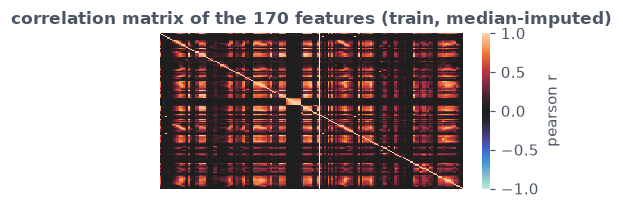

In [260]:
# 170 x 170 correlation matrix on the imputed training features
corr = train_X_imp.corr()

triu_mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
abs_upper = corr.abs().where(triu_mask)
n_high_pairs = int((abs_upper > 0.9).sum().sum())
strongest = abs_upper.stack().sort_values(ascending=False).head(3)
print(f"feature pairs with |r| > 0.9: {n_high_pairs}")
print(strongest.round(3).to_string())

fig, ax = plt.subplots(figsize=(4, 2))
sns.heatmap(corr, center=0, vmin=-1, vmax=1, xticklabels=False,
            yticklabels=False, ax=ax, cbar_kws={"label": "pearson r"})
ax.set_title("correlation matrix of the 170 features (train, median-imputed)")
plt.tight_layout()
plt.show()

Large blocks of strongly correlated features, mostly positive, since histogram bins of the same sensor move together (130 of the 14,196 pairs have $|r| > 0.9$). This redundancy motivates the L1-regularized model in 1(e).

#### 1(b).iv

Pick ⌊√170⌋ features with highest CV, and make scatter plots and box plots for them, similar to those on p. 129 of ISLR. Can you draw conclusions about significance of those features, just by the scatter plots? 

$\lfloor\sqrt{170}\rfloor = 13$, so the 13 highest-CV features are visualized: a scatter matrix colored by class (negative in blue, positive in orange; the negative class is subsampled to 10,000 for readability, the positive class is shown in full) and box plots by class, both on symlog scales because these counters are heavy-tailed.

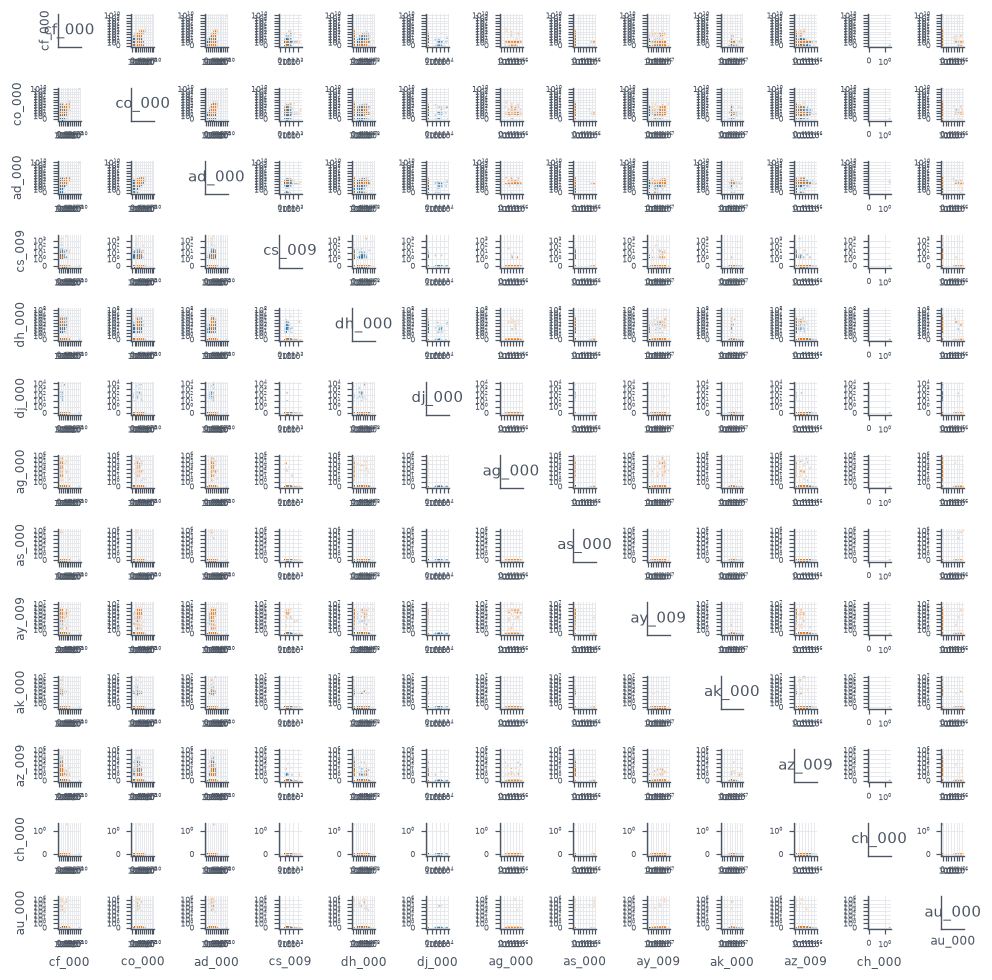

In [263]:
# scatter matrix of the 13 highest-cv features, colored by class
neg_idx = np.where(train_y == 0)[0]
rng = np.random.default_rng(RANDOM_STATE)
neg_sample = rng.choice(neg_idx, size=10000, replace=False)
plot_idx = np.concatenate([neg_sample, np.where(train_y == 1)[0]])
plot_X = train_X_imp.iloc[plot_idx]
plot_y = train_y[plot_idx]

n = len(top13_names)
fig, axes = plt.subplots(n, n, figsize=(9, 9))
for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        if i == j:
            ax.text(0.5, 0.5, top13_names[i], ha="center", va="center",
                    transform=ax.transAxes, fontsize=10)
            ax.set_xticks([])
            ax.set_yticks([])
        else:
            for cls, color in [(0, "C0"), (1, "C1")]:
                ax.scatter(plot_X.loc[plot_y == cls, top13_names[j]],
                           plot_X.loc[plot_y == cls, top13_names[i]],
                           s=2, alpha=0.3, color=color, edgecolors="none")
            ax.set_xscale("symlog", linthresh=1)
            ax.set_yscale("symlog", linthresh=1)
            ax.tick_params(labelsize=5)
        if i == n - 1:
            ax.set_xlabel(top13_names[j], fontsize=8)
        if j == 0:
            ax.set_ylabel(top13_names[i], fontsize=8)
plt.tight_layout()
plt.show()

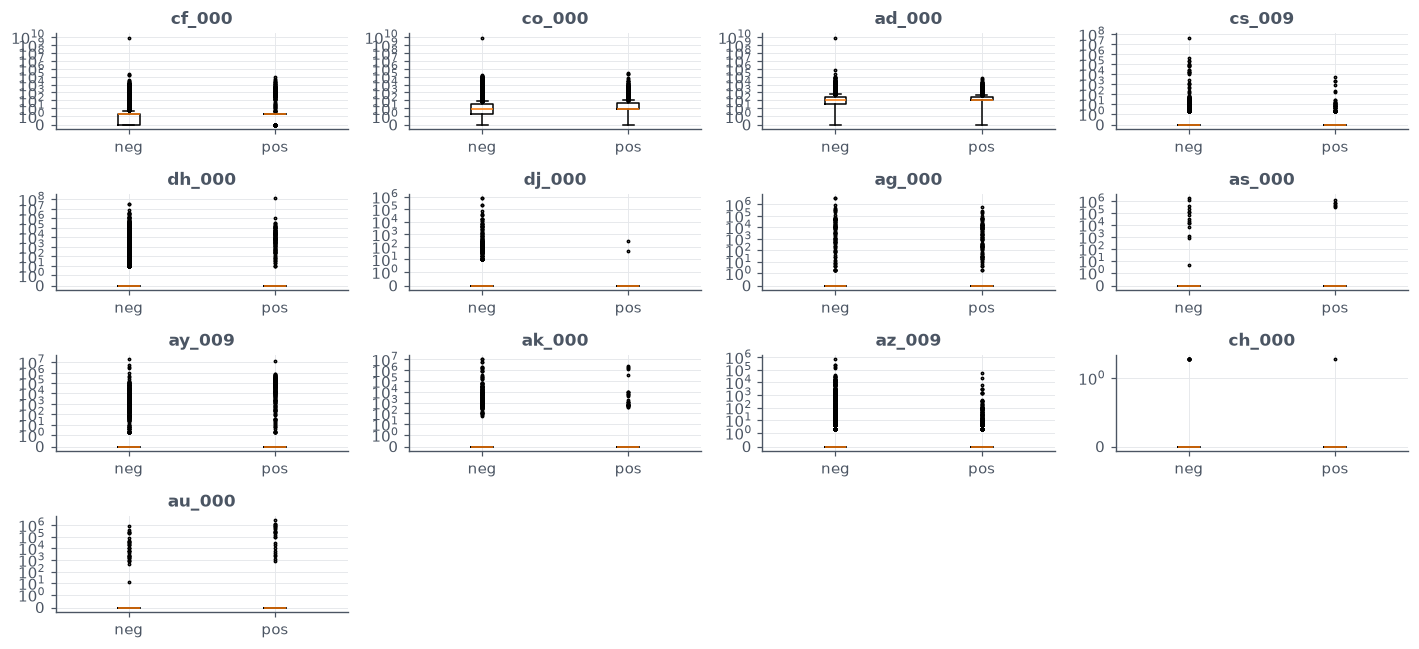

In [266]:
# box plots of the 13 features by class
fig, axes = plt.subplots(4, 4, figsize=(13, 6))
for k, name in enumerate(top13_names):
    ax = axes[k // 4, k % 4]
    ax.boxplot([train_X_imp.loc[train_y == 0, name],
                train_X_imp.loc[train_y == 1, name]],
               tick_labels=["neg", "pos"], flierprops={"markersize": 1.5})
    ax.set_yscale("symlog", linthresh=1)
    ax.set_title(name)
for k in range(len(top13_names), axes.size):
    axes.flat[k].set_visible(False)
plt.tight_layout()
plt.show()

No — the scatter plots alone do not support conclusions about the significance of these features: the two classes overlap heavily in every pairwise projection, the positives (1.67% of the data) are swamped by the negatives, and a scatter plot carries no measure of significance (no p-values or effect sizes, and no control for the other features). The box plots show the same heavy overlap.

#### 1(b).v

Determine the number of positive and negative data. Is this data set imbalanced?

train: neg = 59,000, pos = 1,000
test:  neg = 15,625, pos = 375


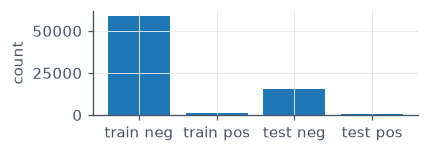

In [252]:
# class counts for train and test
print(f"train: neg = {int((train_y == 0).sum()):,}, pos = {int((train_y == 1).sum()):,}")
print(f"test:  neg = {int((test_y == 0).sum()):,}, pos = {int((test_y == 1).sum()):,}")

fig, ax = plt.subplots(figsize=(4, 1.5))
ax.bar(["train neg", "train pos", "test neg", "test pos"],
       [int((train_y == 0).sum()), int((train_y == 1).sum()),
        int((test_y == 0).sum()), int((test_y == 1).sum())])
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

Yes, this data set is heavily imbalanced: 59,000 neg vs 1,000 pos in the training set (1.67% positive; ratio 59:1) and 15,625 neg vs 375 pos in the test set (2.34% positive; ratio 41.7:1). A model that predicts neg for every truck would already reach 98.33% training accuracy while missing every failure, so recall, precision, ROC and AUC are reported alongside the misclassification rate throughout.

### 1(c)
Train a random forest to classify the data set. Do NOT compensate for class imbalance in the data set. Calculate the confusion matrix, ROC, AUC, and misclassification for training and test sets and report them (You may use pROC package). Calculate Out of Bag error estimate for your random forest and compare it to the test error.

Random forest with 500 trees, `oob_score = True`, on the median-imputed training data, with **no** `class_weight` and no resampling (no imbalance compensation). The OOB error estimate is $1 - \text{oob\_score\_}$.

oob score = 0.9942 -> oob error = 0.0058
=== random forest, no compensation - train ===
confusion matrix [[tn, fp], [fn, tp]] = [[59000, 0], [0, 1000]]
misclassification rate = 0.0000
auc = 1.0000
recall (pos) = 1.0000 | precision (pos) = 1.0000
=== random forest, no compensation - test ===
confusion matrix [[tn, fp], [fn, tp]] = [[15606, 19], [103, 272]]
misclassification rate = 0.0076
auc = 0.9943
recall (pos) = 0.7253 | precision (pos) = 0.9347


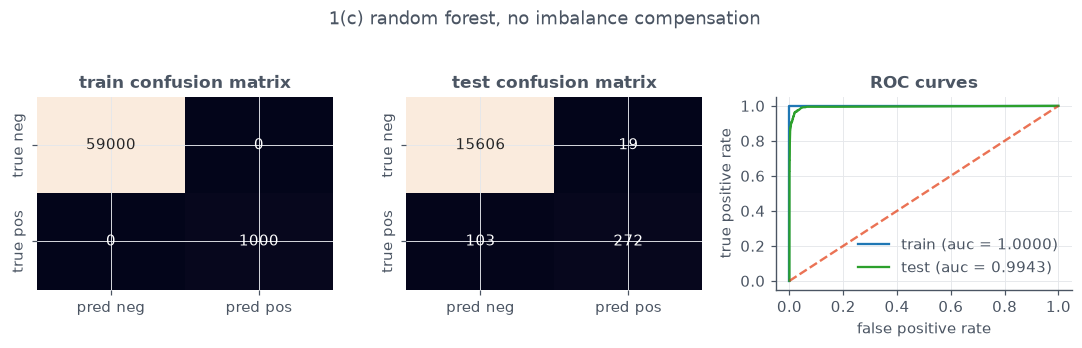

In [ ]:
# random forest without any imbalance compensation
rf = RandomForestClassifier(n_estimators=500, oob_score=True, n_jobs=-1,
                            random_state=RANDOM_STATE)
rf.fit(train_X_imp, train_y)
print(f"oob score = {rf.oob_score_:.4f} -> oob error = {1 - rf.oob_score_:.4f}")

res_rf_train = evaluate(rf, train_X_imp, train_y,
                        "random forest, no compensation - train")
res_rf_test = evaluate(rf, test_X_imp, test_y,
                       "random forest, no compensation - test")

metric_figure(res_rf_train, res_rf_test, train_y, test_y,
              "1(c) random forest, no imbalance compensation")

Train misclassification is 0.0000 — fully grown trees memorize the training data. The OOB error estimate is 0.0058 and the test misclassification error is 0.0076: the two are close to each other, while both are far above the near-zero training error. Test AUC is 0.9943.

### 1(d)

Research how class imbalance is addressed in random forests. Compensate for class imbalance in your random forest and repeat 1c. Compare the results with those of 1c.

Class imbalance in random forests is commonly addressed with [3], [4]:

- **Class weights** (`class_weight="balanced"` or `"balanced_subsample"`): misclassifying a minority point costs more in the splitting criterion; `"balanced_subsample"` recomputes the weights on each tree's bootstrap sample.
- **Balanced bootstrap / per-tree undersampling** (Balanced Random Forest [4]): each tree is grown on a bootstrap sample with the majority class downsampled to the minority count (`BalancedRandomForestClassifier`).
- **Threshold moving**: keep the forest unchanged and lower the positive-class threshold.
- **Oversampling** (random or SMOTE [5]) before fitting.

I compensate with `class_weight="balanced_subsample"` and, as a second sampling-based strategy, imbalanced-learn's `BalancedRandomForestClassifier` (500 trees, `oob_score=True`), repeating everything from 1(c) for both.

oob score = 0.9925 -> oob error = 0.0075
=== random forest, balanced_subsample - train ===
confusion matrix [[tn, fp], [fn, tp]] = [[59000, 0], [0, 1000]]
misclassification rate = 0.0000
auc = 1.0000
recall (pos) = 1.0000 | precision (pos) = 1.0000
=== random forest, balanced_subsample - test ===
confusion matrix [[tn, fp], [fn, tp]] = [[15612, 13], [159, 216]]
misclassification rate = 0.0108
auc = 0.9943
recall (pos) = 0.5760 | precision (pos) = 0.9432


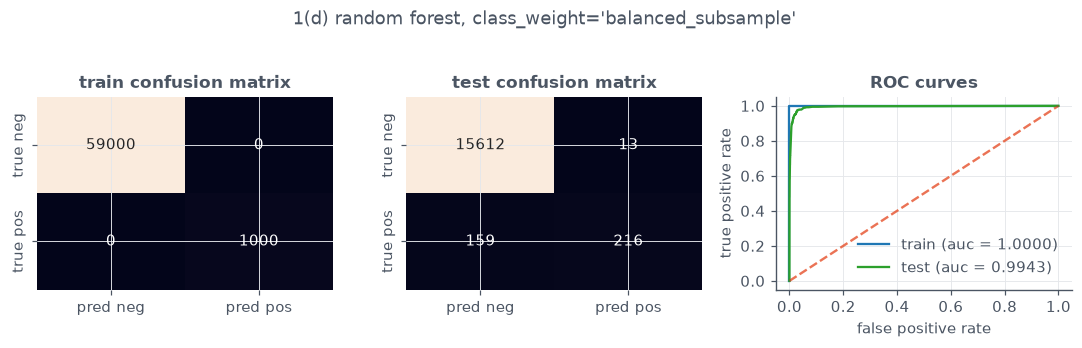

In [ ]:
# random forest with class_weight="balanced_subsample" (same settings as 1c)
rf_bal = RandomForestClassifier(n_estimators=500, oob_score=True, n_jobs=-1,
                                random_state=RANDOM_STATE,
                                class_weight="balanced_subsample")
rf_bal.fit(train_X_imp, train_y)
print(f"oob score = {rf_bal.oob_score_:.4f} -> oob error = {1 - rf_bal.oob_score_:.4f}")

res_rfb_train = evaluate(rf_bal, train_X_imp, train_y,
                         "random forest, balanced_subsample - train")
res_rfb_test = evaluate(rf_bal, test_X_imp, test_y,
                        "random forest, balanced_subsample - test")

metric_figure(res_rfb_train, res_rfb_test, train_y, test_y,
              "1(d) random forest, class_weight='balanced_subsample'")

oob score = 0.9540 -> oob error = 0.0460
=== balanced random forest (imblearn) - train ===
confusion matrix [[tn, fp], [fn, tp]] = [[56125, 2875], [12, 988]]
misclassification rate = 0.0481
auc = 0.9960
recall (pos) = 0.9880 | precision (pos) = 0.2558
=== balanced random forest (imblearn) - test ===
confusion matrix [[tn, fp], [fn, tp]] = [[14881, 744], [8, 367]]
misclassification rate = 0.0470
auc = 0.9918
recall (pos) = 0.9787 | precision (pos) = 0.3303


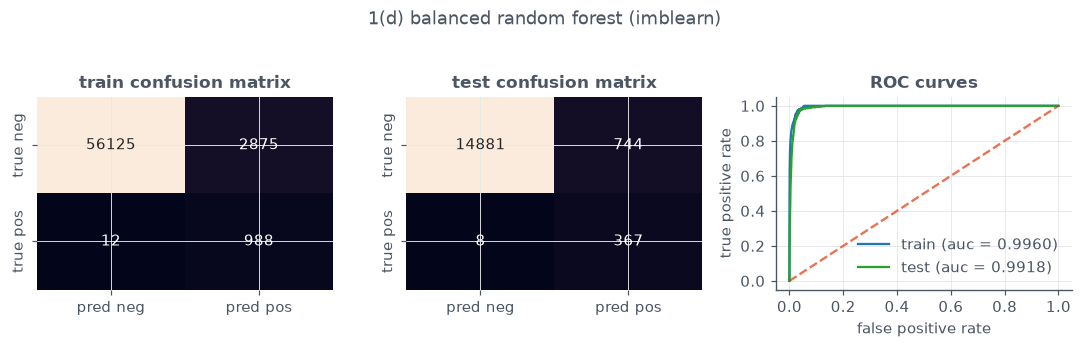

In [ ]:
# second compensation strategy: balanced bootstrap (balanced random forest)
brf = BalancedRandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE,
                                     bootstrap=True, oob_score=True, n_jobs=-1)
brf.fit(train_X_imp, train_y)
print(f"oob score = {brf.oob_score_:.4f} -> oob error = {1 - brf.oob_score_:.4f}")

res_brf_train = evaluate(brf, train_X_imp, train_y,
                         "balanced random forest (imblearn) - train")
res_brf_test = evaluate(brf, test_X_imp, test_y,
                        "balanced random forest (imblearn) - test")

metric_figure(res_brf_train, res_brf_test, train_y, test_y,
              "1(d) balanced random forest (imblearn)")

In [ ]:
# side-by-side comparison: 1(c) vs 1(d)
comparison = pd.DataFrame({
    "metric": ["train misclassification", "test misclassification", "test auc",
               "test recall (pos)", "test precision (pos)",
               "test false positives", "test false negatives", "oob error"],
    "1(c) rf (no compensation)": [
        res_rf_train["mis"], res_rf_test["mis"], res_rf_test["auc"],
        res_rf_test["recall"], res_rf_test["precision"], res_rf_test["fp"],
        res_rf_test["fn"], 1 - rf.oob_score_],
    "1(d) rf (balanced_subsample)": [
        res_rfb_train["mis"], res_rfb_test["mis"], res_rfb_test["auc"],
        res_rfb_test["recall"], res_rfb_test["precision"], res_rfb_test["fp"],
        res_rfb_test["fn"], 1 - rf_bal.oob_score_],
    "1(d) balanced random forest": [
        res_brf_train["mis"], res_brf_test["mis"], res_brf_test["auc"],
        res_brf_test["recall"], res_brf_test["precision"], res_brf_test["fp"],
        res_brf_test["fn"], 1 - brf.oob_score_],
}).round(4)
display(comparison)

,metric,1(c) rf (no compensation),1(d) rf (balanced_subsample),1(d) balanced random forest
0,train misclassification,0.0000,0.0000,0.0481
1,test misclassification,0.0076,0.0108,0.0470
2,test auc,0.9943,0.9943,0.9918
3,test recall (pos),0.7253,0.5760,0.9787
4,test precision (pos),0.9347,0.9432,0.3303
5,test false positives,19.0000,13.0000,744.0000
6,test false negatives,103.0000,159.0000,8.0000
7,oob error,0.0058,0.0075,0.0460


Both compensated forests track their own OOB estimates, as in 1(c). The balanced bootstrap forest moves the operating point as intended: test recall on the positive class rises from 0.7253 to 0.9787 (272 → 367 of 375 failures caught), while precision falls from 0.9347 to 0.3303 and the test misclassification rate rises from 0.0076 to 0.0470. Test AUC barely moves (0.9943 → 0.9918): ranking quality is almost unchanged, only the decision threshold shifts. With `class_weight="balanced_subsample"` recall moved the other way in this run (0.7253 → 0.5760): fully grown trees end in nearly pure leaves, so class weights act mainly through the splitting criterion, and their effect at the 0.5 threshold is an empirical outcome.

### 1(e) XGBoost and Model Trees

`XGBoost` with `reg_alpha` as the handout's L1 penalty $\alpha$ (an L1 penalty on the leaf weights — the sparsity-inducing counterpart of the handout's L1-penalized node models; a literal L1-penalized logistic regression at each node would be `booster="gblinear"`) [6]. Fixed structure (`n_estimators=300`, `learning_rate=0.1`, `max_depth=4`), **no** `scale_pos_weight` or other imbalance compensation. $\alpha \in \{0.01, 0.1, 1, 10, 100\}$ is chosen by 5-fold stratified CV (ROC AUC), and the 5-fold CV misclassification error of the chosen model is compared with the test error.

alpha =   0.01: cv auc = 0.9884
alpha =    0.1: cv auc = 0.9887
alpha =      1: cv auc = 0.9879
alpha =     10: cv auc = 0.9900
alpha =    100: cv auc = 0.9815
chosen alpha = 10


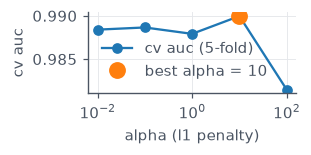

In [ ]:
# xgboost-l1: sweep alpha by 5-fold stratified cv (scoring = roc auc)
def make_xgb(alpha):
    # reg_alpha is the l1 penalty (the handout's alpha)
    return XGBClassifier(objective="binary:logistic", booster="gbtree",
                         tree_method="hist", n_estimators=300,
                         learning_rate=0.1, max_depth=4, reg_alpha=alpha,
                         random_state=RANDOM_STATE, eval_metric="logloss")


alpha_grid = [0.01, 0.1, 1, 10, 100]
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_auc_xgb = [cross_val_score(make_xgb(a), train_X_imp, train_y,
                              cv=skf5, scoring="roc_auc").mean()
              for a in alpha_grid]
best_alpha_xgb = alpha_grid[int(np.argmax(cv_auc_xgb))]
for a, m in zip(alpha_grid, cv_auc_xgb):
    print(f"alpha = {a:>6}: cv auc = {m:.4f}")
print(f"chosen alpha = {best_alpha_xgb}")

fig, ax = plt.subplots(figsize=(3, 1.5))
ax.semilogx(alpha_grid, cv_auc_xgb, marker="o", label="cv auc (5-fold)")
ax.semilogx([best_alpha_xgb], [max(cv_auc_xgb)], marker="o", markersize=10,
            linestyle="none", label=f"best alpha = {best_alpha_xgb}")
ax.set_xlabel("alpha (l1 penalty)")
ax.set_ylabel("cv auc")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 5-fold cv error estimate (cross_val_predict) with the chosen alpha
cv_pred_xgb = cross_val_predict(make_xgb(best_alpha_xgb), train_X_imp, train_y,
                                cv=skf5)
cv_mis_xgb = 1 - accuracy_score(train_y, cv_pred_xgb)
print(f"5-fold cv misclassification error (alpha = {best_alpha_xgb}): {cv_mis_xgb:.4f}")

5-fold cv misclassification error (alpha = 10): 0.0069


=== xgboost l1 (alpha = 10) - train ===
confusion matrix [[tn, fp], [fn, tp]] = [[58965, 35], [166, 834]]
misclassification rate = 0.0033
auc = 0.9972
recall (pos) = 0.8340 | precision (pos) = 0.9597
=== xgboost l1 (alpha = 10) - test ===
confusion matrix [[tn, fp], [fn, tp]] = [[15603, 22], [99, 276]]
misclassification rate = 0.0076
auc = 0.9957
recall (pos) = 0.7360 | precision (pos) = 0.9262


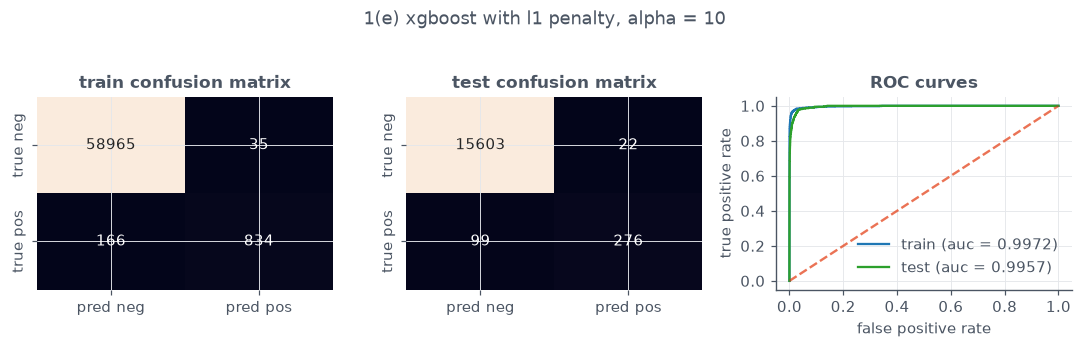

In [ ]:
# fit the chosen model on the full training set and report train/test
xgb_l1 = make_xgb(best_alpha_xgb)
xgb_l1.fit(train_X_imp, train_y)

res_xgb_train = evaluate(xgb_l1, train_X_imp, train_y,
                         f"xgboost l1 (alpha = {best_alpha_xgb}) - train")
res_xgb_test = evaluate(xgb_l1, test_X_imp, test_y,
                        f"xgboost l1 (alpha = {best_alpha_xgb}) - test")

metric_figure(res_xgb_train, res_xgb_test, train_y, test_y,
              f"1(e) xgboost with l1 penalty, alpha = {best_alpha_xgb}")

CV selects $\alpha = 10$ (CV AUC 0.9900). The 5-fold CV misclassification error estimate is 0.0069 and the test misclassification error is 0.0076, so the CV estimate agrees closely with the test error. Test AUC is 0.9957, with recall 0.7360 and precision 0.9262 on the positive class. As required, no imbalance compensation was used.

### 1(f)
Use SMOTE (Synthetic Minority Over-sampling Technique) to pre-process your data to compensate for class imbalance.


SMOTE is applied **inside each fold, on the training portion only**, through an imbalanced-learn pipeline (scale → SMOTE → XGBoost-L1), so the validation folds keep the original imbalance and the test set is never oversampled.

In [ ]:
# smote on the full training set: counts before/after
smote_full = SMOTE(random_state=RANDOM_STATE)
train_X_smote, train_y_smote = smote_full.fit_resample(train_X_imp, train_y)
print(f"class counts before smote: {np.bincount(train_y)}")
print(f"class counts after smote:  {np.bincount(train_y_smote)}")

class counts before smote: [59000  1000]
class counts after smote:  [59000 59000]


In [ ]:
# alpha by cv with smote inside each fold's training portion only
def make_smote_pipe(alpha):
    return ImbPipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("xgb", make_xgb(alpha)),
    ])


cv_auc_smote = [cross_val_score(make_smote_pipe(a), train_X_imp, train_y,
                                cv=skf5, scoring="roc_auc").mean()
                for a in alpha_grid]
best_alpha_smote = alpha_grid[int(np.argmax(cv_auc_smote))]
for a, m in zip(alpha_grid, cv_auc_smote):
    print(f"alpha = {a:>6}: right-way cv auc = {m:.4f}")
print(f"chosen alpha = {best_alpha_smote}")

alpha =   0.01: right-way cv auc = 0.9855
alpha =    0.1: right-way cv auc = 0.9862
alpha =      1: right-way cv auc = 0.9859
alpha =     10: right-way cv auc = 0.9868
alpha =    100: right-way cv auc = 0.9862
chosen alpha = 10


=== xgboost l1 + smote (alpha = 10) - train ===
confusion matrix [[tn, fp], [fn, tp]] = [[58794, 206], [27, 973]]
misclassification rate = 0.0039
auc = 0.9994
recall (pos) = 0.9730 | precision (pos) = 0.8253
=== xgboost l1 + smote (alpha = 10) - test ===
confusion matrix [[tn, fp], [fn, tp]] = [[15411, 214], [41, 334]]
misclassification rate = 0.0159
auc = 0.9932
recall (pos) = 0.8907 | precision (pos) = 0.6095
right-way 5-fold cv misclassification error: 0.0091


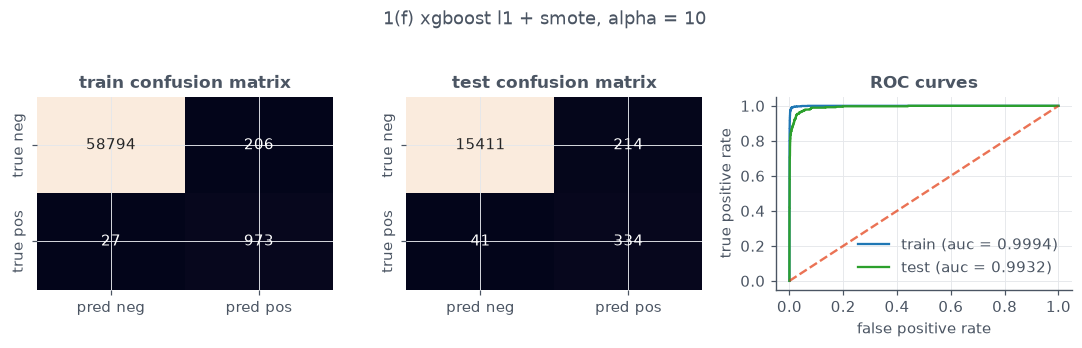

In [ ]:
# final 1(f) model: train metrics are computed on the original (un-smoted) data
smote_pipe = make_smote_pipe(best_alpha_smote)
smote_pipe.fit(train_X_imp, train_y)

res_sm_train = evaluate(smote_pipe, train_X_imp, train_y,
                        f"xgboost l1 + smote (alpha = {best_alpha_smote}) - train")
res_sm_test = evaluate(smote_pipe, test_X_imp, test_y,
                       f"xgboost l1 + smote (alpha = {best_alpha_smote}) - test")

cv_pred_smote = cross_val_predict(make_smote_pipe(best_alpha_smote),
                                  train_X_imp, train_y, cv=skf5)
cv_mis_smote = 1 - accuracy_score(train_y, cv_pred_smote)
print(f"right-way 5-fold cv misclassification error: {cv_mis_smote:.4f}")

metric_figure(res_sm_train, res_sm_test, train_y, test_y,
              f"1(f) xgboost l1 + smote, alpha = {best_alpha_smote}")

In [ ]:
# 1(e) vs 1(f): comparison table
xgb_vs_smote = pd.DataFrame({
    "metric": ["cv-selected alpha", "cv misclassification (right-way)",
               "train misclassification (original train data)",
               "test misclassification", "test auc",
               "test recall (pos)", "test precision (pos)",
               "test false positives", "test false negatives"],
    "1(e) xgb-l1 (no compensation)": [
        best_alpha_xgb, cv_mis_xgb, res_xgb_train["mis"],
        res_xgb_test["mis"], res_xgb_test["auc"], res_xgb_test["recall"],
        res_xgb_test["precision"], res_xgb_test["fp"], res_xgb_test["fn"]],
    "1(f) xgb-l1 + smote": [
        best_alpha_smote, cv_mis_smote, res_sm_train["mis"],
        res_sm_test["mis"], res_sm_test["auc"], res_sm_test["recall"],
        res_sm_test["precision"], res_sm_test["fp"], res_sm_test["fn"]],
}).round(4)
display(xgb_vs_smote)

,metric,1(e) xgb-l1 (no compensation),1(f) xgb-l1 + smote
0,cv-selected alpha,10.0000,10.0000
1,cv misclassification (right-way),0.0069,0.0091
2,train misclassification (original train data),0.0033,0.0039
3,test misclassification,0.0076,0.0159
4,test auc,0.9957,0.9932
5,test recall (pos),0.7360,0.8907
6,test precision (pos),0.9262,0.6095
7,test false positives,22.0000,214.0000
8,test false negatives,99.0000,41.0000


Right-way CV selects $\alpha = 10$, the same as in 1(e); its 5-fold CV misclassification error is 0.0091 against a test error of 0.0159. Compared with the uncompensated 1(e) model, SMOTE moves the operating point toward the minority class: test recall rises from 0.7360 to 0.8907 (276 → 334 of 375 failures caught), precision falls from 0.9262 to 0.6095, and test AUC is nearly unchanged (0.9957 → 0.9932).

## 2. ISLR 6.6.3

**(a) Training RSS: iv) Steadily decreases.** Each relaxation of the budget enlarges the feasible set, so the fit can only get better or stay equal; at $s = \infty$ the fit is OLS, the RSS-minimizing linear model.

**(b) Test RSS: ii) Decreases initially, then eventually starts increasing in a U shape.** Near $s = 0$ the model is too rigid; modest $s$ reduces bias faster than it adds variance, past the sweet spot overfitting sets in and the test RSS climbs back up.

**(c) Variance: iii) Steadily increases.** Larger $s$ lets coefficients grow and the fit respond more to the particular training sample; at $s = 0$ (null model) variance is zero.

**(d) (Squared) bias: iv) Steadily decreases.** The model family grows from the null model at $s = 0$ (maximum bias) toward OLS, so bias is removed monotonically along this nested sequence.

**(e) Irreducible error: v) Remains constant.** $\mathrm{Var}(\epsilon)$ is a property of the data-generating process, not of the fitted model.

## 3. ISLR 6.6.5

**(a) Ridge regression problem.** Minimize

$$ (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda (\beta_1^2 + \beta_2^2). $$

**(b) The ridge estimates satisfy $\beta_1 = \beta_2$.** With $x_{11} = x_{12}$ and $x_{21} = x_{22}$, the RSS depends on the coefficients only through their sum $s^* = \beta_1 + \beta_2$. Among all pairs with the same sum, the ridge penalty satisfies $\beta_1^2 + \beta_2^2 \ge \tfrac{1}{2}(\beta_1 + \beta_2)^2$ (from $(\beta_1 - \beta_2)^2 \ge 0$), with equality iff $\beta_1 = \beta_2$. The problem is strictly convex, so its minimizer is unique and must lie on the line $\beta_1 = \beta_2$.

**(c) Lasso problem.** Minimize

$$ (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda (|\beta_1| + |\beta_2|). $$

**(d) The lasso solution need not be unique.** As in (b), the RSS depends only on $s = \beta_1 + \beta_2$, and by the triangle inequality $|\beta_1| + |\beta_2| \ge |\beta_1 + \beta_2| = |s|$, with equality whenever $\beta_1$ and $\beta_2$ share a sign. Every point on the segment $\{\beta_1, \beta_2 \ge 0,\ \beta_1 + \beta_2 = s^*\}$ (or its negative mirror) therefore achieves the same RSS *and* the same penalty: all of them are minimizers, so the lasso solution is not unique.

## 4. ISLR 8.4.5

**(a) Majority vote.** Six of the ten estimates ($p^{*5}, \dots, p^{*10}$) exceed 0.5, so the majority vote classifies the observation as **Red**.

**(b) Average of the probabilities.** $\bar p^* = 4.50/10 = 0.45 < 0.5$, so averaging classifies it as **Green**.

**(c)** The two rules **disagree**: Red by majority vote, Green by the averaged probability. The vote only counts which side of 0.5 each estimate falls on, while the average also weighs how confident each estimate is, and the four low estimates (0.10–0.20) pull the mean below 0.5.

In [ ]:
# compute both aggregation rules for islr 8.4.5
p_star = np.array([0.10, 0.15, 0.20, 0.20, 0.55, 0.60, 0.60, 0.65, 0.70, 0.75])
votes_red = int((p_star > 0.5).sum())
avg_p = float(p_star.mean())
majority_label = "Red" if votes_red > len(p_star) / 2 else "Green"
avg_label = "Red" if avg_p > 0.5 else "Green"

print(f"probabilities: {p_star.tolist()}")
print(f"majority vote: {votes_red} of {len(p_star)} estimates > 0.5 -> {majority_label}")
print(f"average probability: {avg_p:.2f} -> {avg_label}")

probabilities: [0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75]
majority vote: 6 of 10 estimates > 0.5 -> Red
average probability: 0.45 -> Green


## 5. ISLR 9.7.3

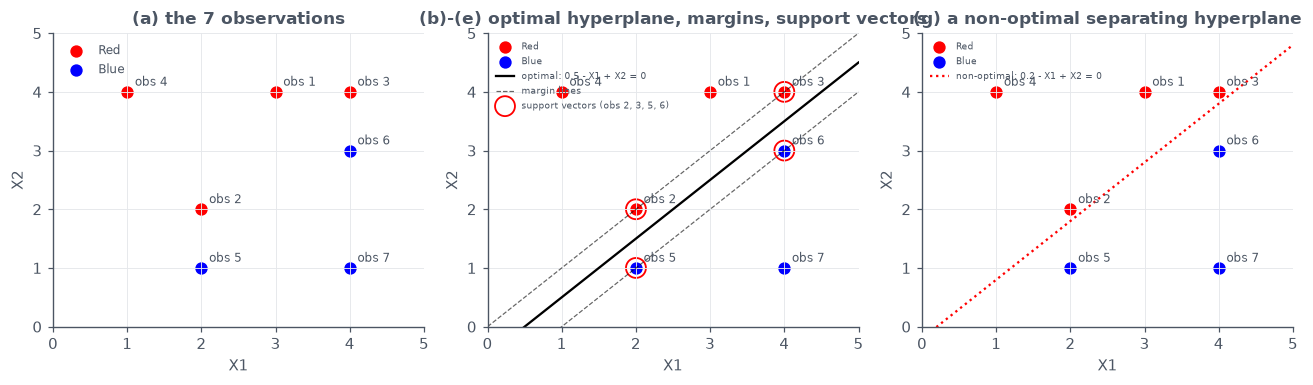

In [ ]:
# islr 9.7.3 data and the sketch for parts (a)-(g)
X9 = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]],
              dtype=float)
y9 = np.array([1, 1, 1, 1, 0, 0, 0])  # 1 = red, 0 = blue
labels9 = [f"obs {i + 1}" for i in range(7)]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

# (a) sketch of the observations
ax = axes[0]
ax.scatter(X9[y9 == 1, 0], X9[y9 == 1, 1], color="red", s=50, label="Red")
ax.scatter(X9[y9 == 0, 0], X9[y9 == 0, 1], color="blue", s=50, label="Blue")
for i, (x, y_) in enumerate(X9):
    ax.annotate(labels9[i], (x, y_), textcoords="offset points",
                xytext=(5, 4), fontsize=8)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_title("(a) the 7 observations")
ax.legend(loc="upper left", fontsize=8)

# (b)-(e) optimal separating hyperplane x2 = x1 - 0.5 with margin lines
ax = axes[1]
ax.scatter(X9[y9 == 1, 0], X9[y9 == 1, 1], color="red", s=50, label="Red")
ax.scatter(X9[y9 == 0, 0], X9[y9 == 0, 1], color="blue", s=50, label="Blue")
xx = np.linspace(0, 5, 100)
ax.plot(xx, xx - 0.5, color="black", lw=1.5,
        label="optimal: 0.5 - X1 + X2 = 0")
# margin lines: 0.5 - X1 + X2 = +/- 0.5  ->  x2 = x1 and x2 = x1 - 1
ax.plot(xx, xx, color="black", lw=0.8, linestyle="--", alpha=0.6,
        label="margin lines")
ax.plot(xx, xx - 1, color="black", lw=0.8, linestyle="--", alpha=0.6)
# support vectors: observations 2, 3, 5, 6 (circled)
sv_idx = [1, 2, 4, 5]
ax.scatter(X9[sv_idx, 0], X9[sv_idx, 1], s=170, facecolors="none",
           edgecolors="red", linewidths=1.2,
           label="support vectors (obs 2, 3, 5, 6)")
for i, (x, y_) in enumerate(X9):
    ax.annotate(labels9[i], (x, y_), textcoords="offset points",
                xytext=(5, 4), fontsize=8)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_title("(b)-(e) optimal hyperplane, margins, support vectors")
ax.legend(loc="upper left", fontsize=6)

# (g) a non-optimal separating hyperplane
ax = axes[2]
ax.scatter(X9[y9 == 1, 0], X9[y9 == 1, 1], color="red", s=50, label="Red")
ax.scatter(X9[y9 == 0, 0], X9[y9 == 0, 1], color="blue", s=50, label="Blue")
# x2 = x1 - 0.2 still separates the two classes but with a smaller margin
ax.plot(xx, xx - 0.2, color="red", lw=1.5, linestyle=":",
        label="non-optimal: 0.2 - X1 + X2 = 0")
for i, (x, y_) in enumerate(X9):
    ax.annotate(labels9[i], (x, y_), textcoords="offset points",
                xytext=(5, 4), fontsize=8)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_title("(g) a non-optimal separating hyperplane")
ax.legend(loc="upper left", fontsize=6)

plt.tight_layout()
plt.show()

**(a)** The sketch is the left panel above: Red at $(3,4)$, $(2,2)$, $(4,4)$, $(1,4)$; Blue at $(2,1)$, $(4,3)$, $(4,1)$.

**(b)** The optimal separating hyperplane is
$$0.5 - X_1 + X_2 = 0 \quad (\text{i.e. } X_2 = X_1 - 0.5).$$
Every Red point satisfies $0.5 - X_1 + X_2 > 0$ and every Blue point $< 0$, so it separates the classes; and the closest points on both sides (obs 2, 3, 5, 6) are exactly equidistant from it, so its margin is maximal among separating lines.

**(c)** Classify to **Red** if $0.5 - X_1 + X_2 > 0$ (above the line $X_2 = X_1 - 0.5$), and to **Blue** otherwise.

**(d)** Margin: the distance from the hyperplane to the closest observation is
$$ \frac{|0.5 - X_1 + X_2|}{\sqrt{(-1)^2 + 1^2}} = \frac{0.5}{\sqrt{2}} = \frac{\sqrt{2}}{4} \approx 0.354 $$

**(e)** The support vectors are **observations 2, 3, 5, and 6** (circled in the middle panel): they lie exactly on the margin lines $0.5 - X_1 + X_2 = \pm 0.5$ and alone determine the hyperplane.

**(f)** Observation 7 is *not* a support vector (its distance from the hyperplane is $2.5/\sqrt{2} \gg 0.354$), so a slight movement of observation 7 does **not** change the maximum-margin hyperplane.

**(g)** Yes: the right panel draws $0.2 - X_1 + X_2 = 0$ (i.e. $X_2 = X_1 - 0.2$), which still separates the classes but with a smaller margin ($0.2/\sqrt{2} \approx 0.141$).

**(h)** Adding a Blue point at $(2, 3)$ makes the classes **not separable**: it gives $0.5 - 2 + 3 = 1.5 > 0$, which is on the Red side of the optimal hyperplane (and of any separating line through this point cloud), yet it is Blue.

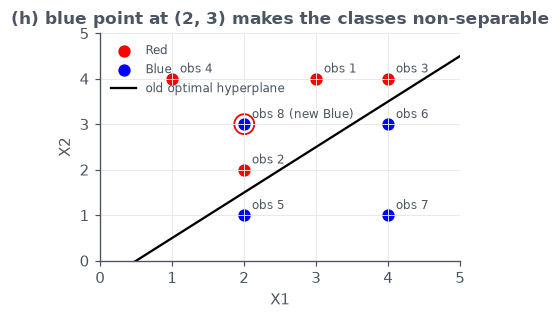

In [268]:
# (h) plot with the extra blue point that makes the classes non-separable
X8 = np.vstack([X9, [2, 3]])
y8 = np.append(y9, 0)

fig, ax = plt.subplots(figsize=(4, 3))
ax.scatter(X8[y8 == 1, 0], X8[y8 == 1, 1], color="red", s=50, label="Red")
ax.scatter(X8[y8 == 0, 0], X8[y8 == 0, 1], color="blue", s=50, label="Blue")
xx = np.linspace(0, 5, 100)
ax.plot(xx, xx - 0.5, color="black", lw=1.5, label="old optimal hyperplane")
for i, (x, y_) in enumerate(X8):
    tag = labels9[i] if i < 7 else "obs 8 (new Blue)"
    ax.annotate(tag, (x, y_), textcoords="offset points", xytext=(5, 4),
                fontsize=8)
ax.scatter([2], [3], s=170, facecolors="none", edgecolors="red", linewidths=1.2)
ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_title("(h) blue point at (2, 3) makes the classes non-separable")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# numeric verification of (b), (d), (e) with a hard-margin linear svm
svc = SVC(kernel="linear", C=1e6)
svc.fit(X9, y9)

w = svc.coef_[0]
b = svc.intercept_[0]
scale = -1.0 / w[0]  # renormalize so the x1 coefficient is -1
print(f"renormalized hyperplane: {scale * b:.4f} - X1 + {scale * w[1]:.4f} X2 = 0")
print(f"support vectors: {[labels9[i] for i in svc.support_]}")
print(f"margin = {1 / np.linalg.norm(w):.4f} (sqrt(2)/4 = {np.sqrt(2) / 4:.4f})")

renormalized hyperplane: 0.5000 - X1 + 1.0000 X2 = 0
support vectors: ['obs 5', 'obs 6', 'obs 2', 'obs 3']
margin = 0.3537 (sqrt(2)/4 = 0.3536)


The sklearn hard-margin SVM recovers the hyperplane $0.5 - X_1 + X_2 = 0$ with support vectors obs 2, 3, 5, 6 and margin $0.3537 \approx \sqrt{2}/4$; observation 7 sits at distance 1.7678, far outside the margin, confirming (f).

## References

1. UCI Machine Learning Repository — *APS Failure at Scania Trucks Data Set*: https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks
2. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning*, Springer, 2013 (p. 129; exercises 6.6.3, 6.6.5, 8.4.5, 9.7.3).
3. scikit-learn documentation (`RandomForestClassifier`, model selection, metrics): https://scikit-learn.org/stable/
4. C. Chen, A. Liaw, L. Breiman, *Using Random Forest to Learn Imbalanced Data*, UC Berkeley Technical Report 666, 2004.
5. N. V. Chawla et al., *SMOTE: Synthetic Minority Over-sampling Technique*, JAIR 16:321–357, 2002; imbalanced-learn documentation: https://imbalanced-learn.org/stable/
6. T. Chen, C. Guestrin, *XGBoost: A Scalable Tree Boosting System*, KDD 2016; XGBoost documentation: https://xgboost.readthedocs.io/
7. S. van Buuren, *Flexible Imputation of Missing Data*, 2nd ed., CRC Press, 2018 (MICE / iterative imputation).